# Step 1: Gene Prediction Evaluation

This notebook evaluates the structural concordance of gene predictions from various prokaryotic annotation tools (Prokka, Bakta, PGAP, eggNOG) against the NCBI RefSeq ground truth. 

It standardizes the GFF outputs, calculates performance metrics (Precision, Recall, F1-Score), visualizes intersections using UpSet plots, and exports the concordant CDS sets for downstream functional analysis.

In [1]:
import sys
import requests
import os
import pandas as pd
from pathlib import Path
from IPython.display import display

from benchannot.prokaryotic.gene_prediction import (
    clean_prokka_gff,
    load_gff,
    standardize_gff,
    calculate_structural_metrics,
    export_concordant_cds,
)
from benchannot.paths import (
    pgap_annotation_path,
    project_paths,
    validate_required_inputs,
)
from benchannot.plotting import apply_style, plot_upset_panels
from benchannot.prokaryotic.gene_prediction import concordance_membership


In [2]:
ORGANISMS = ["bacillus_subtilis", "escherichia_coli"]
TOOLS_TO_EVALUATE = ["Prokka", "Bakta", "PGAP", "eggNOG"]
UPSET_ORDER = ["Reference", "PGAP", "Bakta", "Prokka", "eggNOG"]
DATASET = "reproduced"  # "origin" or "reproduced"
PATHS = project_paths(DATASET)

PROKARYOTE_TOOLS_DIR = PATHS.prokaryote_tools
GENOME_PROKARYOTE_DIR = PATHS.genome_prokaryote
OUTPUT_DIR = PATHS.analysis_output / "prokaryotic"
FIGURE_DIR = PATHS.figures / "prokaryotic"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset: {DATASET}")
print(f"Tool inputs: {PROKARYOTE_TOOLS_DIR}")
print(f"Analysis outputs: {OUTPUT_DIR}")

Dataset: reproduced
Tool inputs: /home/bruno/BenchAnnot/data/reproduced/prokaryote_output_tools
Analysis outputs: /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic


## 1. Process, Evaluate, and Export

Iterate through each organism to clean the Prokka GFF, standardize all tool outputs into a unified format, generate concordance plots, calculate F1 metrics, and export the true positive CDS matches.

In [3]:
gene_prediction_inputs = {}
for organism in ORGANISMS:
    gene_prediction_inputs.update(
        {
            f"{organism} Prokka GFF ({DATASET})": (
                PROKARYOTE_TOOLS_DIR / "prokka" / f"{organism}.gff"
            ),
            f"{organism} Bakta GFF3 ({DATASET})": (
                PROKARYOTE_TOOLS_DIR / "bakta" / f"{organism}.gff3"
            ),
            f"{organism} PGAP GFF ({DATASET})": pgap_annotation_path(
                PATHS, organism, "gff"
            ),
            f"{organism} eggNOG decorated GFF ({DATASET})": (
                PROKARYOTE_TOOLS_DIR
                / "eggnog"
                / f"{organism}.emapper.decorated.gff"
            ),
            f"{organism} NCBI RefSeq reference GFF": (
                GENOME_PROKARYOTE_DIR / f"{organism}.gff"
            ),
        }
    )

validate_required_inputs(
    gene_prediction_inputs,
    context=f"prokaryotic gene prediction ({DATASET})",
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

  Processing: BACILLUS_SUBTILIS
  Cleaned: /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/bacillus_subtilis_prokka_cleaned.gff
Metrics (Bacillus_subtilis)


,Annotation Tool,Exact Matches (TP),Spurious/Shifted (FP),Missed Genes (FN),Precision,Recall,F1-Score
0,PGAP,4149,165,91,0.961800,0.978500,0.970100
1,Bakta,3753,472,487,0.888300,0.885100,0.886700
2,Prokka,3743,471,497,0.888200,0.882800,0.885500
3,eggNOG,3744,482,496,0.885900,0.883000,0.884500


  Exporting concordant CDS records to /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/bacillus_subtilis_concordant_CDS.csv
-> Exported 3718 concordant CDS records to /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/bacillus_subtilis_concordant_CDS.csv
  Processing: ESCHERICHIA_COLI
  Cleaned: /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/escherichia_coli_prokka_cleaned.gff
Metrics (Escherichia_coli)


,Annotation Tool,Exact Matches (TP),Spurious/Shifted (FP),Missed Genes (FN),Precision,Recall,F1-Score
0,PGAP,4086,337,254,0.923800,0.941500,0.932600
1,Bakta,3951,421,389,0.903700,0.910400,0.907000
2,Prokka,3889,416,451,0.903400,0.896100,0.899700
3,eggNOG,3889,430,451,0.900400,0.896100,0.898300


  Exporting concordant CDS records to /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/escherichia_coli_concordant_CDS.csv
-> Exported 3794 concordant CDS records to /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic/escherichia_coli_concordant_CDS.csv
Saved /home/bruno/BenchAnnot/figures/prokaryotic/gene_prediction_upset_merged.png


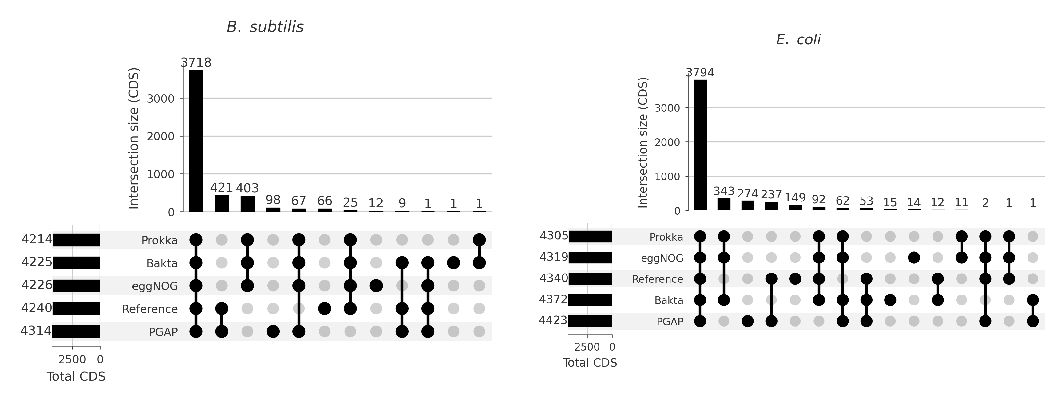

PosixPath('/home/bruno/BenchAnnot/figures/prokaryotic/gene_prediction_upset_merged.png')

In [4]:
upset_memberships = {}
all_metrics = {}

for org in ORGANISMS:
    print(f"  Processing: {org.upper()}")

    PROKKA_RAW = (PROKARYOTE_TOOLS_DIR/"prokka"/f"{org}.gff")
    PROKKA_CLEAN = (OUTPUT_DIR/f"{org}_prokka_cleaned.gff")
    PGAP_RAW = pgap_annotation_path(PATHS, org, "gff")
    BAKTA_RAW = (PROKARYOTE_TOOLS_DIR/"bakta"/f"{org}.gff3")
    EGGNOG_RAW = (PROKARYOTE_TOOLS_DIR/"eggnog"/f"{org}.emapper.decorated.gff")
    GENBANK_PATH = (GENOME_PROKARYOTE_DIR/f"{org}.gff")
    EXPORT_CSV = (OUTPUT_DIR/f"{org}_concordant_CDS.csv")

    clean_prokka_gff(PROKKA_RAW, PROKKA_CLEAN)
    print(f"  Cleaned: {PROKKA_CLEAN}")

    dfs = [
        load_gff(EGGNOG_RAW, "eggNOG"),
        load_gff(BAKTA_RAW, "Bakta"),
        load_gff(PROKKA_CLEAN, "Prokka"),
        load_gff(PGAP_RAW, "PGAP"),
        load_gff(GENBANK_PATH, "Reference"),
    ]

    standardized_dfs = []
    for df in dfs:
        if df["Source"].iloc[0] == "eggNOG":
            standardized_dfs.append(standardize_gff(df, is_eggnog=True))
        else:
            standardized_dfs.append(standardize_gff(df))

    all_gffs = pd.concat(standardized_dfs, ignore_index=True)

    upset_memberships[org] = concordance_membership(all_gffs, UPSET_ORDER)

    print(f"Metrics ({org.capitalize()})")
    df_metrics = calculate_structural_metrics(all_gffs, tools=TOOLS_TO_EVALUATE)

    all_metrics[org] = df_metrics

    display(
        df_metrics.style.background_gradient(
            cmap="Blues", subset=["F1-Score", "Precision", "Recall"]
        )
    )

    print(f"  Exporting concordant CDS records to {EXPORT_CSV}")

    tp_df = export_concordant_cds(all_gffs, TOOLS_TO_EVALUATE, "Reference", EXPORT_CSV)
    print(f"-> Exported {len(tp_df)} concordant CDS records to {EXPORT_CSV}")

apply_style()
plot_upset_panels(
    upset_memberships,
    source_order=UPSET_ORDER,
    ncols=2,
    count_label="CDS",
    save_path=FIGURE_DIR / "gene_prediction_upset_merged.png",
)
